Posição do poço = 10 10
Permeabilidade no bloco do poço = 345.9258015351545 mD
Pressão inicial no bloco do poço = 20.684 MPa
Pressão final no bloco do poço = 17.2114521694196 MPa
Pressão de fundo do poço = 15.0 MPa
Vazão final do poço = -0.030967257231899324 m³/s


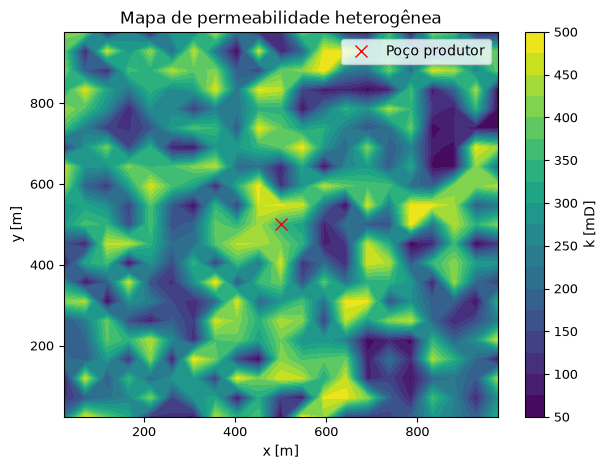

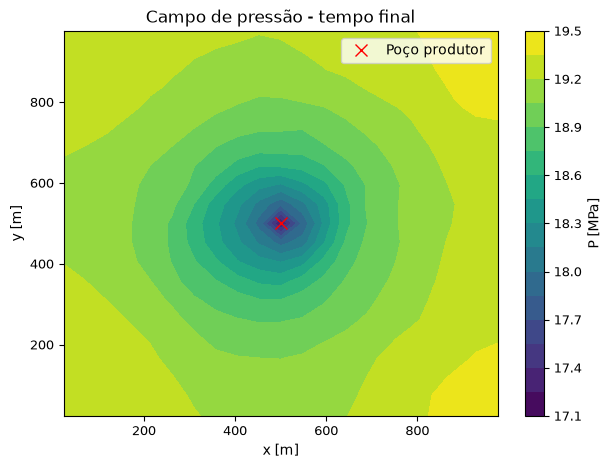

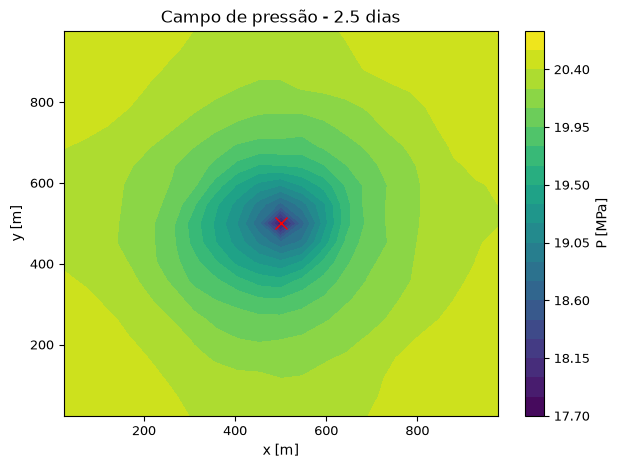

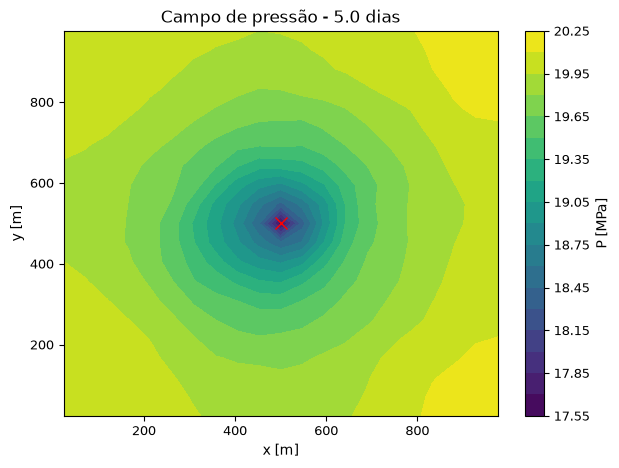

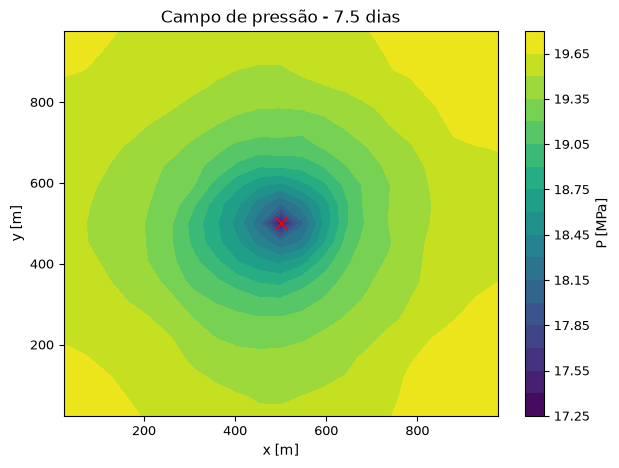

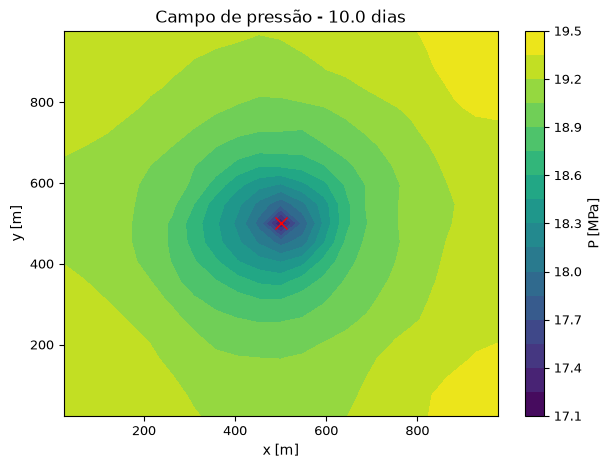

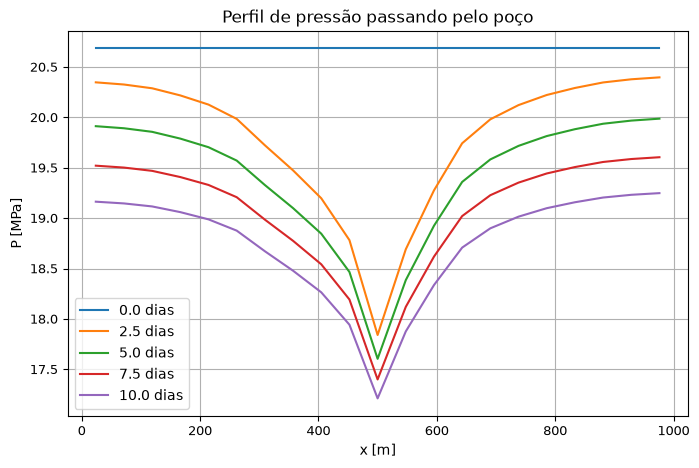

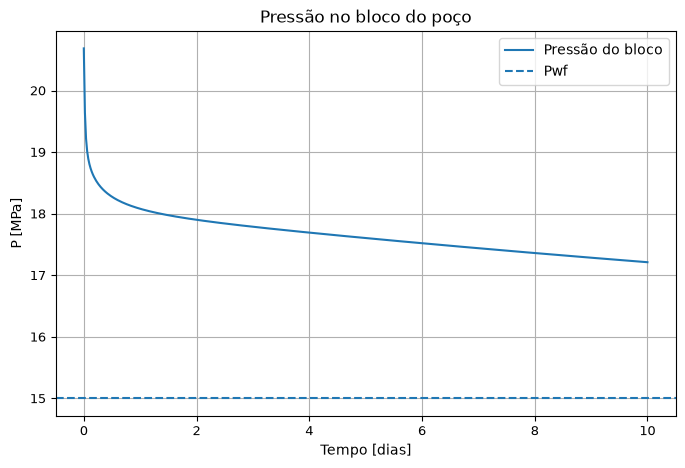

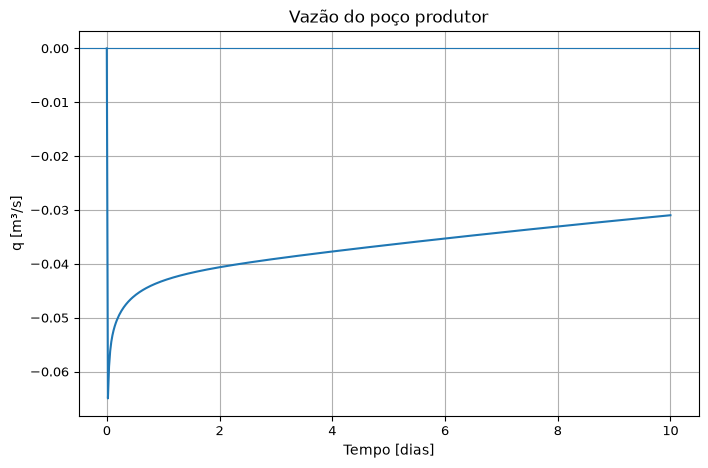

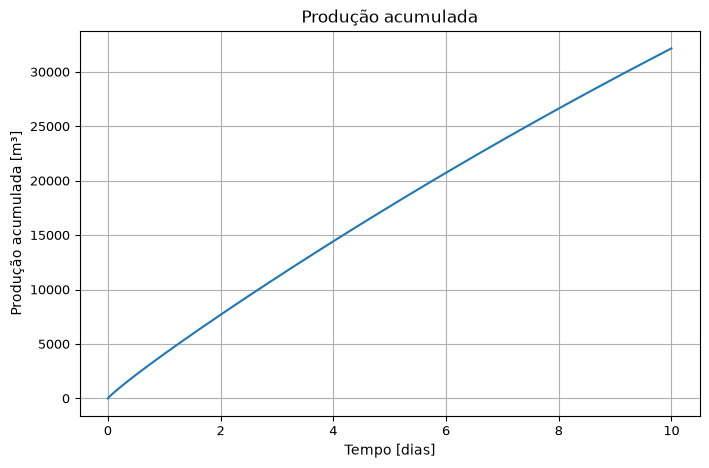

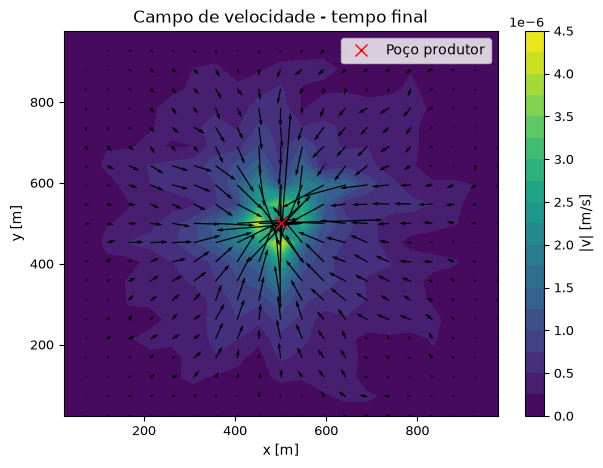

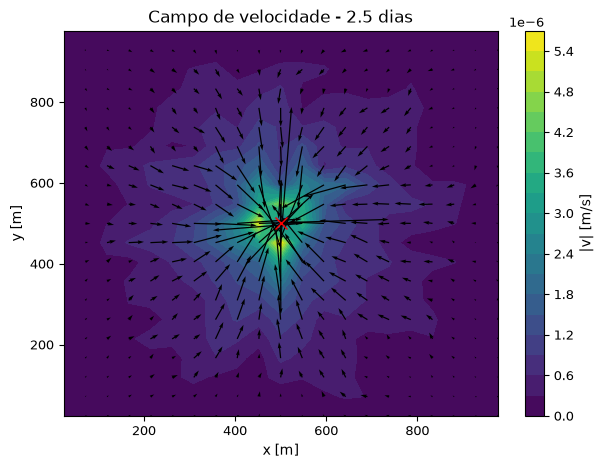

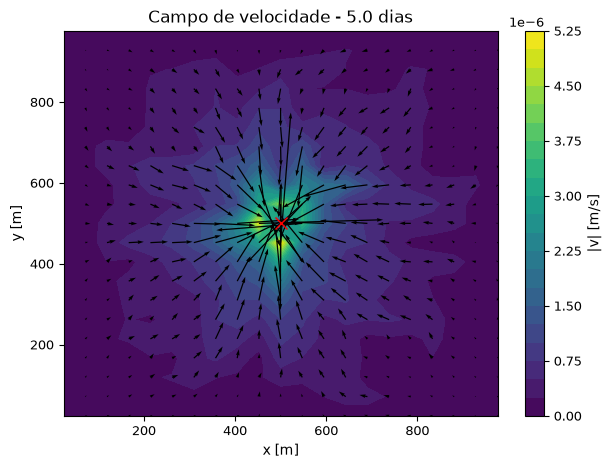

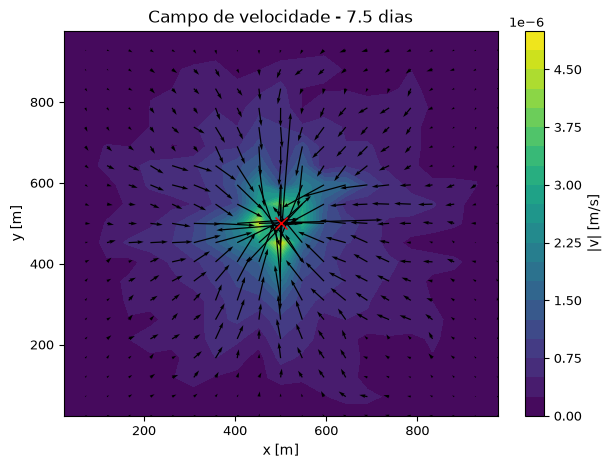

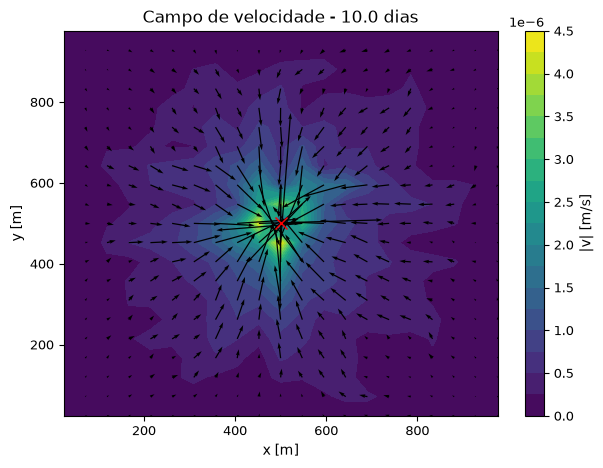

In [1]:
from pathlib import Path
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

import os
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family": "sans-serif", "font.size": 10, "axes.titlesize": 12, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 10, "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"})

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from mdf.implicita_2d import implicita_2d
from core.permeabilidade2d import gerar_permeabilidade, salvar_permeabilidade, carregar_permeabilidade
from core.velocidade2d import calcular_velocidade


_figura_id = 0
def salvar_e_mostrar():
    global _figura_id
    _figura_id += 1
    plt.savefig(RESULTS_DIR / f"produtor_central_{_figura_id:02d}.pdf", dpi=180, bbox_inches="tight")
    plt.show()

# parâmetros

p0 = 20.684e6
pwf = 15.0e6

Lx = 1000.0
Ly = 1000.0

h = 30.0
rw = 0.10

phi = 0.22
ct = 3.046e-9
mu = 1.0e-3

t_d = 10
t_final = t_d * 86400


# malha

nx = 21
ny = 21
nt = 500

dx = Lx / nx
dy = Ly / ny


# permeabilidade heterogênea

arquivo_k = ROOT / "data" / "permeabilidade.csv"

if os.path.exists(arquivo_k):

    k_mD = carregar_permeabilidade(arquivo_k)

else:

    k_mD = gerar_permeabilidade(nx,ny,50,500,seed=42)

    salvar_permeabilidade(k_mD,arquivo_k)


k = k_mD * 9.869233e-16 # conversão mD -> m²


# solução

x, y, t, P, q_poco = implicita_2d(p0,pwf,rw,h,Lx,Ly,k,phi,ct,mu,t_final,nx,ny,nt)
q_producao = np.maximum(-q_poco, 0.0)


# poço

iw = nx // 2
jw = ny // 2

print("Posição do poço =", iw, jw)
print("Permeabilidade no bloco do poço =",k_mD[jw, iw],"mD")
print("Pressão inicial no bloco do poço =",P[0, jw, iw] / 1e6,"MPa")
print("Pressão final no bloco do poço =",P[-1, jw, iw] / 1e6,"MPa")
print("Pressão de fundo do poço =",pwf / 1e6,"MPa")
print("Vazão final do poço =",q_poco[-1],"m³/s")

# malha para gráficos

X, Y = np.meshgrid(x, y)

# mapa de permeabilidade

plt.figure(figsize=(7, 5))

mapa_k = plt.contourf(X,Y,k_mD,levels=20, cmap="viridis")

plt.colorbar(mapa_k,label="k [mD]")
plt.plot(x[iw],y[jw],"rx",markersize=8,label="Poço produtor")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title("Mapa de permeabilidade heterogênea")
plt.legend()

salvar_e_mostrar()

# Campo de pressão no tempo final

plt.figure(figsize=(7, 5))

contorno = plt.contourf(X,Y,P[-1, :, :] / 1e6,levels=20, cmap="viridis")

plt.colorbar(contorno,label="P [MPa]")
plt.plot(x[iw],y[jw],"rx",markersize=8,label="Poço produtor")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title("Campo de pressão - tempo final")
plt.legend()

salvar_e_mostrar()


# campos de pressão em diferentes tempos

tempos_pressao = np.linspace(t_d / 4,t_d,4)

for tempo in tempos_pressao:

    t_escolhido = tempo * 86400

    indice = np.argmin(np.abs(t - t_escolhido))

    plt.figure(figsize=(7, 5))

    contorno = plt.contourf(X,Y,P[indice, :, :] / 1e6,levels=20, cmap="viridis")

    plt.colorbar(contorno,label="P [MPa]")
    plt.plot(x[iw],y[jw],"rx",markersize=8)
    plt.xlabel("x [m]")
    plt.ylabel("y [m]")
    plt.title(f"Campo de pressão - {tempo:.1f} dias")
    salvar_e_mostrar()


# perfil de pressão passando pelo poço
tempos_perfil = np.linspace(0,t_d,5)

plt.figure(figsize=(8, 5))

for tempo in tempos_perfil:
    t_escolhido = tempo * 86400
    indice = np.argmin(np.abs(t - t_escolhido))

    plt.plot(x,P[indice, jw, :] / 1e6,label=f"{tempo:.1f} dias")

plt.xlabel("x [m]")
plt.ylabel("P [MPa]")
plt.title("Perfil de pressão passando pelo poço")
plt.grid()
plt.legend()

salvar_e_mostrar()

# pressão no bloco do poço

plt.figure(figsize=(8, 5))
plt.plot(t / 86400,P[:, jw, iw] / 1e6,label="Pressão do bloco")
plt.axhline(pwf / 1e6,linestyle="--",label="Pwf")
plt.xlabel("Tempo [dias]")
plt.ylabel("P [MPa]")
plt.title("Pressão no bloco do poço")
plt.grid()
plt.legend()

salvar_e_mostrar()


# vazão do poço

plt.figure(figsize=(8, 5))
plt.plot(t / 86400, q_producao)
plt.axhline(0,linewidth=0.8)
plt.xlabel("Tempo [dias]")
plt.ylabel("Vazão de produção [m³/s]")
plt.title("Vazão do poço produtor")
plt.grid()

salvar_e_mostrar()


# produção acumulada

Q_acumulada = np.zeros(len(t))

for n in range(1, len(t)):

    dt_n = t[n] - t[n - 1]
    Q_acumulada[n] = (Q_acumulada[n - 1] + (-q_poco[n]) * dt_n)

plt.figure(figsize=(8, 5))
plt.plot(t / 86400,Q_acumulada)
plt.xlabel("Tempo [dias]")
plt.ylabel("Produção acumulada [m³]")
plt.title("Produção acumulada")
plt.grid()

salvar_e_mostrar()


# campo de velocidade

Vx, Vy, V = calcular_velocidade(P, k, mu, dx, dy)


# campo de velocidade no tempo final

plt.figure(figsize=(7, 5))

velocidade = plt.contourf(X,Y,V[-1],levels=20, cmap="viridis")

plt.colorbar(velocidade,label="|v| [m/s]")
plt.quiver(X,Y,Vx[-1],Vy[-1])
plt.plot(x[iw],y[jw],"rx",markersize=8,label="Poço produtor")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title("Campo de velocidade - tempo final")
plt.legend()

salvar_e_mostrar()


# campos de velocidade em diferentes tempos

tempos_velocidade = np.linspace(t_d / 4,t_d,4)

for tempo in tempos_velocidade:

    t_escolhido = tempo * 86400
    indice = np.argmin(np.abs(t - t_escolhido))

    plt.figure(figsize=(7, 5))

    velocidade = plt.contourf(X,Y,V[indice],levels=20, cmap="viridis")

    plt.colorbar(velocidade,label="|v| [m/s]")
    plt.quiver(X,Y,Vx[indice],Vy[indice])
    plt.plot(x[iw],y[jw],"rx",markersize=8)
    plt.xlabel("x [m]")
    plt.ylabel("y [m]")
    plt.title(f"Campo de velocidade - {tempo:.1f} dias")

    salvar_e_mostrar()


# animação do campo de pressão

fig, ax = plt.subplots(figsize=(7, 5))
p_min = np.min(P[1:] / 1e6)
p_max = np.max(P[1:] / 1e6)
levels_animacao = np.linspace(p_min,p_max,20)

def atualizar(frame):
    ax.clear()
    ax.contourf(X,Y,P[frame, :, :] / 1e6,levels=levels_animacao, cmap="viridis")
    ax.plot(x[iw],y[jw],"rx",markersize=8)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_title(f"Campo de pressão - " f"{t[frame] / 86400:.2f} dias")

frames = np.linspace(1,len(t) - 1,100,dtype=int)
animacao = FuncAnimation(fig, atualizar,frames=frames,interval=100)

plt.close()

HTML(animacao.to_jshtml())


